In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

RAIZ = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
df = pd.read_csv(RAIZ / "data" / "clean" / "ai4i2020_clean.csv")

# Variables nuevas basadas en las reglas físicas de falla
df["power_w"] = df["torque_nm"] * df["rpm"] * 2 * np.pi / 60   # potencia en vatios
df["temp_diff_k"] = df["process_temp_k"] - df["air_temp_k"]    # diferencia de temperatura

# Entradas: SIN twf, hdf, pwf, osf, rnf, udi, product_id ni etiqueta_inconsistente
numericas = ["air_temp_k", "process_temp_k", "rpm", "torque_nm",
             "tool_wear_min", "power_w", "temp_diff_k"]
categoricas = ["type"]

X = df[numericas + categoricas]
y = df["machine_failure"]
print(X.shape, y.shape)
X.head()

(10000, 8) (10000,)


,air_temp_k,process_temp_k,rpm,torque_nm,tool_wear_min,power_w,temp_diff_k,type
0,298.1,308.6,1551,42.8,0,6951.590560,10.5,M
1,298.2,308.7,1408,46.3,3,6826.722724,10.5,L
2,298.1,308.5,1498,49.4,5,7749.387543,10.4,L
3,298.2,308.6,1433,39.5,7,5927.504659,10.4,L
4,298.2,308.7,1408,40.0,9,5897.816608,10.5,L


In [2]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print("Train:", X_train.shape, "| fallas:", y_train.sum(), f"({y_train.mean():.2%})")
print("Test: ", X_test.shape,  "| fallas:", y_test.sum(),  f"({y_test.mean():.2%})")

Train: (8000, 8) | fallas: 271 (3.39%)
Test:  (2000, 8) | fallas: 68 (3.40%)


In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

preproceso = ColumnTransformer([
    ("num", StandardScaler(), numericas),
    ("cat", OneHotEncoder(drop="first"), categoricas),
])

modelo_base = Pipeline([
    ("prep", preproceso),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)),
])

modelo_base.fit(X_train, y_train)
pred_base = modelo_base.predict(X_test)
print("REGRESIÓN LOGÍSTICA (línea base)")
print(classification_report(y_test, pred_base, target_names=["Sin falla", "Falla"], digits=3))

REGRESIÓN LOGÍSTICA (línea base)
              precision    recall  f1-score   support

   Sin falla      0.995     0.859     0.922      1932
       Falla      0.178     0.868     0.295        68

    accuracy                          0.859      2000
   macro avg      0.586     0.863     0.608      2000
weighted avg      0.967     0.859     0.900      2000



In [4]:
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

modelo_rf = Pipeline([
    ("prep", preproceso),
    ("clf", RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                   random_state=42, n_jobs=-1)),
])

modelo_gb = Pipeline([
    ("prep", preproceso),
    ("clf", HistGradientBoostingClassifier(class_weight="balanced", random_state=42)),
])

for nombre, m in [("RANDOM FOREST", modelo_rf), ("GRADIENT BOOSTING", modelo_gb)]:
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    print(nombre)
    print(classification_report(y_test, pred, target_names=["Sin falla", "Falla"], digits=3))

RANDOM FOREST
              precision    recall  f1-score   support

   Sin falla      0.993     0.997     0.995      1932
       Falla      0.917     0.809     0.859        68

    accuracy                          0.991      2000
   macro avg      0.955     0.903     0.927      2000
weighted avg      0.991     0.991     0.991      2000

GRADIENT BOOSTING
              precision    recall  f1-score   support

   Sin falla      0.994     0.993     0.994      1932
       Falla      0.803     0.838     0.820        68

    accuracy                          0.988      2000
   macro avg      0.899     0.915     0.907      2000
weighted avg      0.988     0.988     0.988      2000



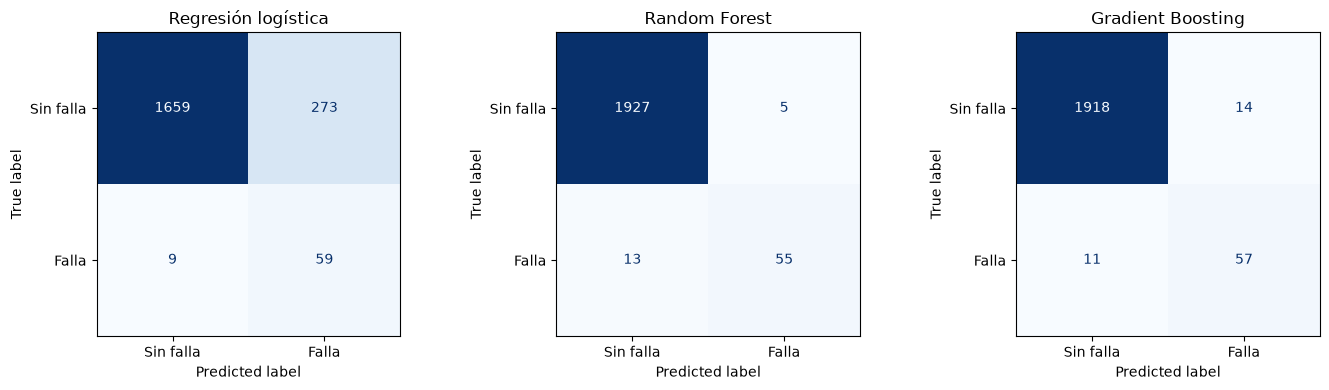

In [5]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

FIG = RAIZ / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

modelos = {
    "Regresión logística": modelo_base,
    "Random Forest": modelo_rf,
    "Gradient Boosting": modelo_gb,
}

fig, ejes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (nombre, m) in zip(ejes, modelos.items()):
    ConfusionMatrixDisplay.from_estimator(
        m, X_test, y_test, display_labels=["Sin falla", "Falla"],
        cmap="Blues", colorbar=False, ax=ax
    )
    ax.set_title(nombre)
plt.tight_layout()
plt.savefig(FIG / "5_matrices_confusion.png", dpi=150)
plt.show()

In [7]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metricas = {"precision": "precision", "recall": "recall", "f1": "f1"}

filas = []
for nombre, m in modelos.items():
    r = cross_validate(m, X_train, y_train, cv=cv, scoring=metricas, n_jobs=-1)
    filas.append({
        "modelo": nombre,
        "precision": f"{r['test_precision'].mean():.3f} ± {r['test_precision'].std():.3f}",
        "recall":    f"{r['test_recall'].mean():.3f} ± {r['test_recall'].std():.3f}",
        "f1":        f"{r['test_f1'].mean():.3f} ± {r['test_f1'].std():.3f}",
    })

pd.DataFrame(filas)

,modelo,precision,recall,f1
0,Regresión logística,0.165 ± 0.012,0.823 ± 0.048,0.275 ± 0.018
1,Random Forest,0.867 ± 0.046,0.753 ± 0.061,0.806 ± 0.053
2,Gradient Boosting,0.863 ± 0.055,0.804 ± 0.026,0.831 ± 0.025


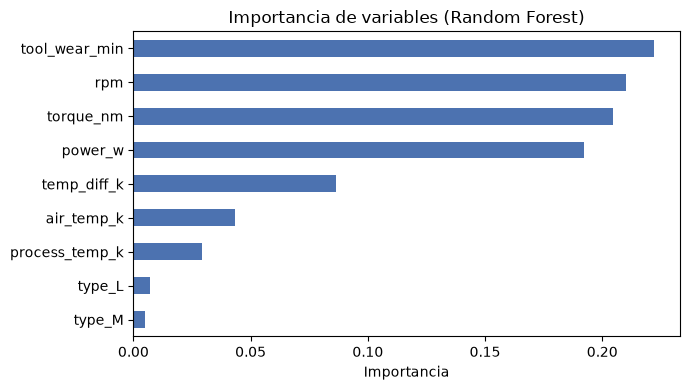

tool_wear_min     0.222
rpm               0.210
torque_nm         0.205
power_w           0.192
temp_diff_k       0.087
air_temp_k        0.043
process_temp_k    0.029
type_L            0.007
type_M            0.005
dtype: float64

In [8]:
nombres = modelo_rf.named_steps["prep"].get_feature_names_out()
nombres = [n.split("__")[1] for n in nombres]
importancias = modelo_rf.named_steps["clf"].feature_importances_

imp = pd.Series(importancias, index=nombres).sort_values()

fig, ax = plt.subplots(figsize=(7, 4))
imp.plot.barh(ax=ax, color="#4C72B0")
ax.set_title("Importancia de variables (Random Forest)")
ax.set_xlabel("Importancia")
plt.tight_layout()
plt.savefig(FIG / "6_importancia_variables.png", dpi=150)
plt.show()

imp.sort_values(ascending=False).round(3)

## Conclusiones
1. Solo el 3.4 % de las lecturas son fallas (339 de 10 000), así que el accuracy engaña: se evaluó con precision, recall y F1 sobre la clase "Falla".
2. La regresión logística detecta 59 de 68 fallas (recall 0.868) pero genera 273 falsas alarmas (precision 0.178), lo que la hace inviable: una frontera lineal no captura que las fallas ocurren en los extremos de torque y rpm.
3. Random Forest y Gradient Boosting superan ampliamente la línea base. En validación cruzada, Gradient Boosting obtuvo F1 0.831 ± 0.025 y recall 0.804 contra F1 0.806 ± 0.053 y recall 0.753 de Random Forest, y fue el modelo más estable, por lo que se eligió como modelo final.
4. Las variables más influyentes son desgaste de herramienta, rpm, torque y potencia (≈83 % de la importancia en Random Forest); la potencia, construida a partir de torque y rpm, resultó clave, mientras que el tipo de producto y las temperaturas por separado aportan poco.
5. Limitaciones: el dataset es sintético y la prueba tiene solo 68 fallas. El modelo final aún deja pasar 11 de ellas (16 %). Con más tiempo se ajustaría el umbral de decisión para priorizar recall, se afinarían hiperparámetros y se validaría con datos reales.

In [12]:
import joblib
import sklearn, pandas, numpy, matplotlib, seaborn

MODELOS = RAIZ / "models"
MODELOS.mkdir(exist_ok=True)
joblib.dump(modelo_gb, MODELOS / "modelo_gb.joblib")

# Verificar que carga y predice igual
cargado = joblib.load(MODELOS / "modelo_gb.joblib")
print("Predicciones idénticas:", (cargado.predict(X_test) == modelo_gb.predict(X_test)).all())

# Versiones para requirements.txt (el modelo guardado exige la misma versión de scikit-learn)
print(f"scikit-learn=={sklearn.__version__}")
print(f"pandas=={pandas.__version__}")
print(f"numpy=={numpy.__version__}")
print(f"matplotlib=={matplotlib.__version__}")
print(f"seaborn=={seaborn.__version__}")
print(f"joblib=={joblib.__version__}")


Predicciones idénticas: True
scikit-learn==1.9.0
pandas==3.0.3
numpy==2.4.6
matplotlib==3.11.0
seaborn==0.13.2
joblib==1.5.3
